<a href="https://colab.research.google.com/github/dsouzabrandon02-ops/CSL701-14_Machine-Learning-Lab/blob/main/Eperiments/_of_ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name :  Brandon B Dsouza

Batch : CS01


Roll Number : CS14



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Try to load the dataset. If the local file is not present, we can fetch it directly from a public URL containing the penguins dataset
try:
    # Attempting to load locally if downloaded/placed in folder
    df = pd.read_csv('palmers-penguin-dataset-extended.csv')
    print("Loaded local penguins dataset.")
except FileNotFoundError:
    # Fallback to standard Palmer Penguins dataset from seaborn
    print("Local file not found. Loading standard palmer penguins from seaborn as fallback...")
    df = sns.load_dataset('penguins')
    # Map column names if needed to match the expected schema
    df = df.rename(columns={'bill_length_mm': 'culmen_length_mm', 'bill_depth_mm': 'culmen_depth_mm'})

display(df.head())

Local file not found. Loading standard palmer penguins from seaborn as fallback...


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [2]:
# 1. Handle missing values
# We will drop rows where critical numerical features or target species are null
features = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
df_clean = df.dropna(subset=features + ['species']).copy()

# 2. Select Features (X) and Target (y)
X = df_clean[features]
y = df_clean['species']

# 3. Encode categorical target variable
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print(f"Original shape: {df.shape}, Cleaned shape: {df_clean.shape}")
print(f"Classes encoded: {dict(zip(le.classes_, range(len(le.classes_))))}")

Original shape: (344, 7), Cleaned shape: (342, 7)
Classes encoded: {'Adelie': 0, 'Chinstrap': 1, 'Gentoo': 2}


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [3]:
# Split dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (273, 4)
Testing set shape: (69, 4)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [4]:
# Initialize Decision Tree Classifier using Gini impurity criterion
cart_model = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)

# Fit the model
cart_model.fit(X_train, y_train)

# Make predictions on test set
y_pred_cart = cart_model.predict(X_test)
print("CART Classifier successfully trained and predictions generated.")

CART Classifier successfully trained and predictions generated.


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

CART Model Accuracy: 100.00%



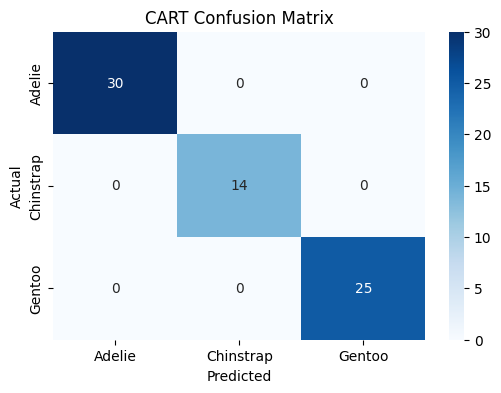

Classification Report for CART Model:
              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



In [5]:
# 1. Accuracy
accuracy_cart = accuracy_score(y_test, y_pred_cart)
print(f"CART Model Accuracy: {accuracy_cart * 100:.2f}%\n")

# 2. Confusion Matrix
cm_cart = confusion_matrix(y_test, y_pred_cart)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_cart, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('CART Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# 3. Classification Report
print("Classification Report for CART Model:")
print(classification_report(y_test, y_pred_cart, target_names=le.classes_))

# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


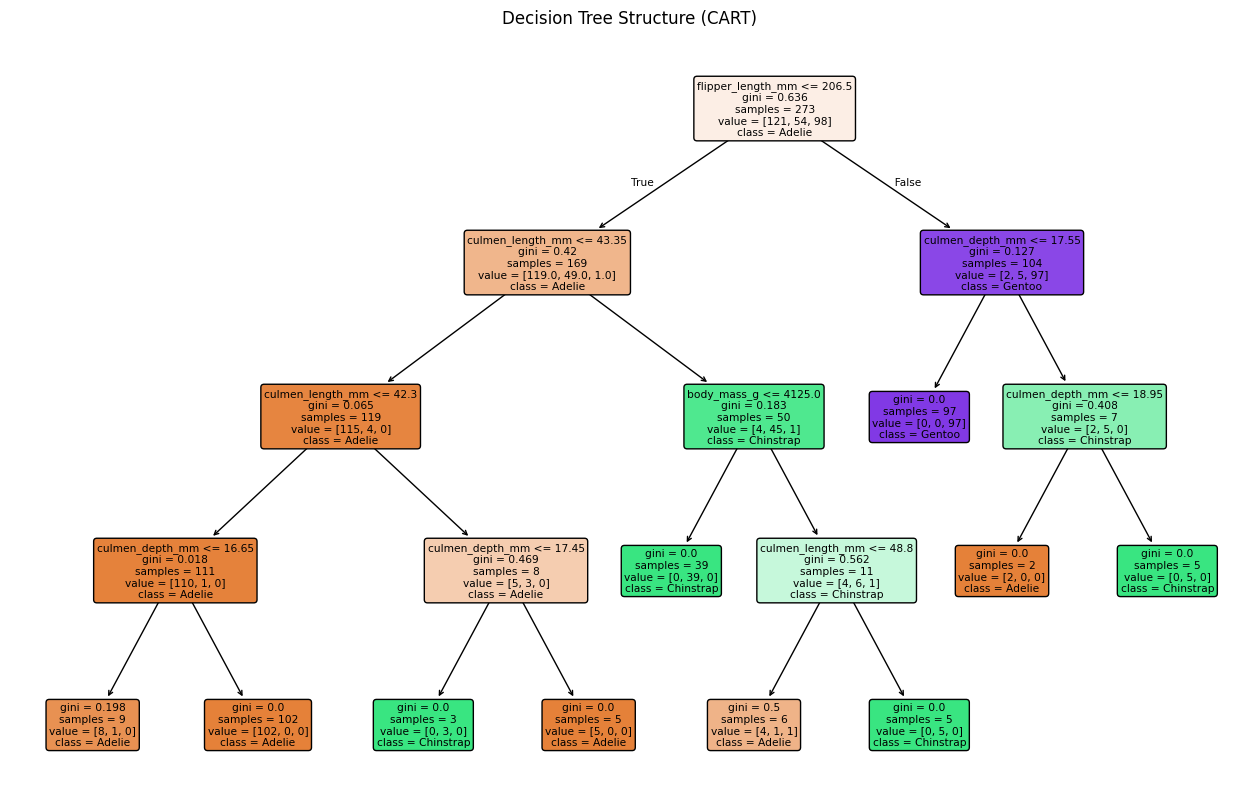

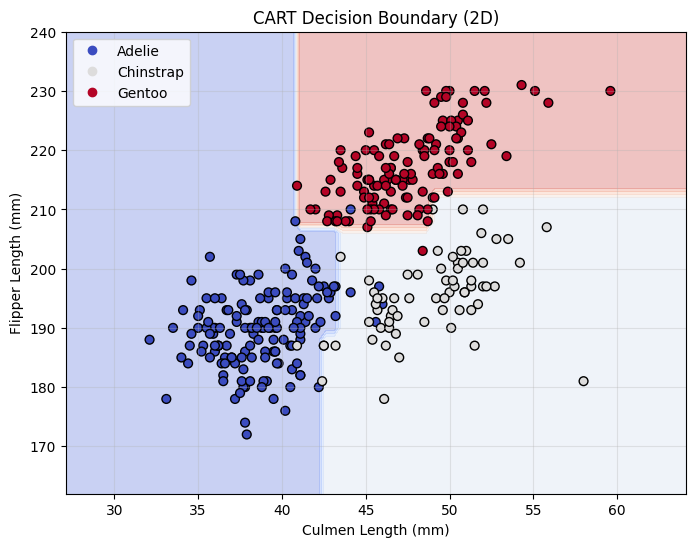

In [6]:
# 1. Plot the decision tree structure
plt.figure(figsize=(16, 10))
plot_tree(cart_model, feature_names=features, class_names=le.classes_, filled=True, rounded=True)
plt.title("Decision Tree Structure (CART)")
plt.show()

# 2. Train a 2D Decision Tree for visualization (using culmen_length_mm and flipper_length_mm)
X_2D = df_clean[['culmen_length_mm', 'flipper_length_mm']].values
y_2D = y_encoded

model_2d_cart = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
model_2d_cart.fit(X_2D, y_2D)

# Helper function to plot decision boundaries
def plot_decision_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 5, X[:, 0].max() + 5
    y_min, y_max = X[:, 1].min() - 10, X[:, 1].max() + 10
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.5), np.arange(y_min, y_max, 2))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='k', s=40)
    plt.title(title)
    plt.xlabel('Culmen Length (mm)')
    plt.ylabel('Flipper Length (mm)')
    plt.legend(handles=scatter.legend_elements()[0], labels=list(le.classes_))
    plt.grid(True, alpha=0.3)

plt.figure(figsize=(8, 6))
plot_decision_boundary(model_2d_cart, X_2D, y_2D, "CART Decision Boundary (2D)")
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

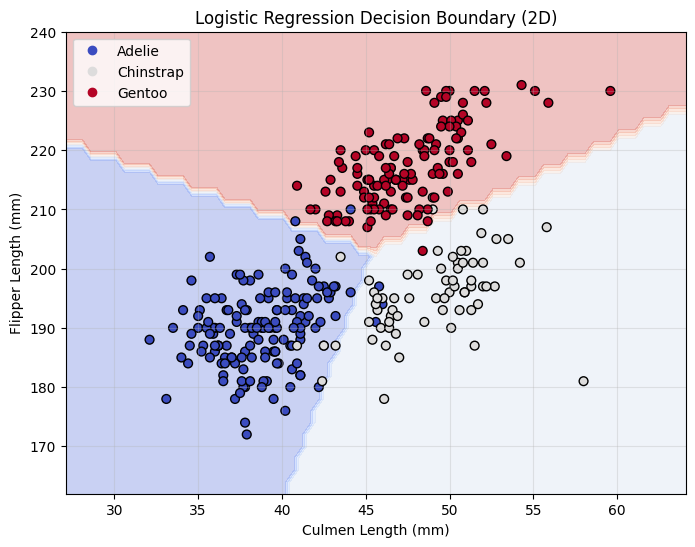

In [7]:
# Train a Logistic Regression model on the same 2D data
model_2d_logreg = LogisticRegression(max_iter=1000, random_state=42)
model_2d_logreg.fit(X_2D, y_2D)

plt.figure(figsize=(8, 6))
plot_decision_boundary(model_2d_logreg, X_2D, y_2D, "Logistic Regression Decision Boundary (2D)")
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

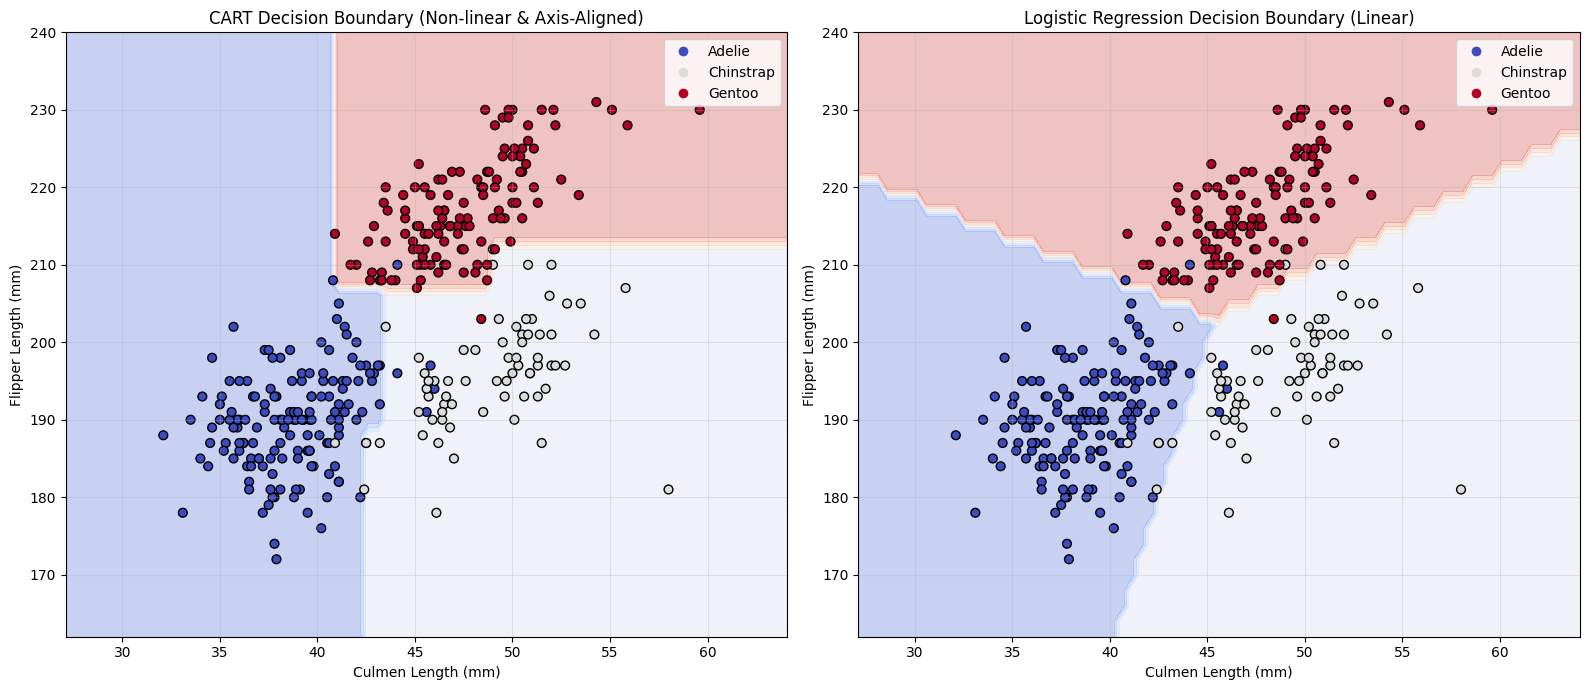

In [8]:
# Plot CART and Logistic Regression boundaries side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

plt.sca(axes[0])
plot_decision_boundary(model_2d_cart, X_2D, y_2D, "CART Decision Boundary (Non-linear & Axis-Aligned)")

plt.sca(axes[1])
plot_decision_boundary(model_2d_logreg, X_2D, y_2D, "Logistic Regression Decision Boundary (Linear)")

plt.tight_layout()
plt.show()

# Evaluate and compare metrics on 2D data for both models
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(X_2D, y_2D, test_size=0.2, random_state=42, stratify=y_2D)

# Train temporary 2D models on train split
m_cart = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42).fit(X_train_2d, y_train_2d)
m_logreg = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_2d, y_train_2d)

y_pred_cart_2d = m_cart.predict(X_test_2d)
y_pred_logreg_2d = m_logreg.predict(X_test_2d)

print("=== Performance Comparison on 2D Feature Subset ===")
print(f"CART 2D Test Accuracy               : {accuracy_score(y_test_2d, y_pred_cart_2d)*100:.2f}%")
print(f"Logistic Regression 2D Test Accuracy : {accuracy_score(y_test_2d, y_pred_logreg_2d)*100:.2f}%")

print("\n--- CART Classifier Report (2D) ---")
print(classification_report(y_test_2d, y_pred_cart_2d, target_names=le.classes_))

print("--- Logistic Regression Classifier Report (2D) ---")
print(classification_report(y_test_2d, y_pred_logreg_2d, target_names=le.classes_))

# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.